# Model C: Isolation Forest anomaly + Denial-of-Wallet (DoW) detection (CloudSense AI)
**Spec:** `IsolationForest(n_estimators=200, contamination=0.01, max_samples='auto', random_state=42)`; features `cost_velocity, request_rate, request_rate_delta, provisioning_frequency, cpu_utilization, network_io, storage_growth_rate, spend_vs_baseline, invocation_rate`; `CostVelocity=(Cost(t)-Cost(t-D))/D` (USD/min, D=5 min); `ProvisioningFrequency=N_create/|t|` (launches/hour over a trailing 30 min); 5-minute windows; fit on predominantly normal history; threshold tuned on labelled windows; consecutive alerts grouped into incidents; the score is **not** a probability; alerts are "DoW candidates", never confirmed attacks.
**Three deployment tiers are compared:** (1) *extended* (CloudWatch + access-log features), (2) *core only* (what CloudWatch alone gives you), (3) *unlabelled* (no labels, threshold from an alert budget).
Logic lives in the importable package `cloudsense/anomaly.py` (training, `StreamScorer` for real time, triage). Synthetic benchmark by default; real-data block below.

In [1]:
import os, sys, json, warnings, logging, zipfile, time, platform
from pathlib import Path
warnings.filterwarnings("ignore"); logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")
def _bootstrap():
    try: import cloudsense; return
    except ImportError: pass
    for c in [Path("."), Path(".."), Path("cloudsense_ml"), Path("/content/cloudsense_ml")]:
        if (c / "cloudsense").exists(): sys.path.insert(0, str(c.resolve())); return
    try:                                                         # Colab: upload cloudsense_ml.zip once
        from google.colab import files
        for n, b in files.upload().items(): open(n, "wb").write(b); zipfile.ZipFile(n).extractall(".")
        sys.path.insert(0, str(Path("cloudsense_ml").resolve()))
    except ImportError: raise ImportError("Put the cloudsense/ package folder next to this notebook (or in ../), or on Colab upload cloudsense_ml.zip")
_bootstrap()
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import cloudsense; print("cloudsense", cloudsense.__version__)
def find_data(files):
    for c in ["data", "../data", "cloudsense_ml/data", "/content/data", "/content/cloudsense_ml/data"]:
        if all((Path(c) / f).exists() for f in files): return Path(c)
    try:
        from google.colab import files as cf; Path("data").mkdir(exist_ok=True)
        for n, b in cf.upload().items(): open(Path("data") / n, "wb").write(b)
        return Path("data")
    except ImportError: raise FileNotFoundError(f"Put {files} in ./data")
def make_outputs(tag):
    out = Path(f"outputs_{tag}"); fig = out / "figures"; art = out / "artifacts"
    for p in (fig, art): p.mkdir(parents=True, exist_ok=True)
    caps = {}
    def savefig(name, caption):
        plt.tight_layout(); plt.savefig(fig / f"{name}.png", dpi=105, bbox_inches="tight"); caps[name] = caption; plt.show()
    return out, fig, art, caps, savefig

from cloudsense import anomaly as an
from cloudsense.common import jdump
from cloudsense.collectors.realtime import RealtimeRunner
from sklearn.metrics import average_precision_score, precision_recall_curve
OUT, FIG, ART, CAPS, savefig = make_outputs("model_c"); DATA = find_data(["C_telemetry_5min.csv"]); print("data:", DATA)

cloudsense 1.0.0


data: ../data


## 1. Load and validate

In [2]:
tele = pd.read_csv(DATA / "C_telemetry_5min.csv", parse_dates=["window_start"])
labels = pd.read_csv(DATA / "C_labels_eval_only.csv", parse_dates=["window_start"]) if (DATA / "C_labels_eval_only.csv").exists() else None     # OPTIONAL, evaluation/tuning only
inc_gt = pd.read_csv(DATA / "C_incident_ground_truth.csv", parse_dates=["start", "end"]); borg = pd.read_csv(DATA / "C_borg_real_reference_windows.csv")
# ---- REAL DATA (optional): build the same frame from CloudWatch + CloudTrail (cost per window is ESTIMATED and reconciled to daily Cost Explorer totals).
# from cloudsense.collectors import get_session; from cloudsense.collectors.pipeline import build_model_c_frame; from cloudsense.collectors.cost_estimate import PriceTable
# s = get_session(profile="cloudsense-readonly", region="ap-south-1")
# tele = build_model_c_frame(s.client("cloudwatch"), "2026-08-20", "2026-10-20", asg_names=["web-asg"], load_balancers=["app/my-alb/123"], functions=["notify-fn"], ct=s.client("cloudtrail"),
#                            prices=PriceTable(ec2_hourly_per_instance=0.10), daily_cost=daily_cost_df, storage_gb=disk_used_series)   # CloudWatch keeps 5-min data ~63 days: store your own history from day 1
# labels = None   # real accounts have no labels -> the notebook's unlabelled mode below applies
raw, dq = an.validate_c(tele); jdump(dq, OUT / "data_quality.json")
print(f"{len(raw)} windows {raw.window_start.min()} -> {raw.window_start.max()}"); print("core columns:", an.CORE_C); print("optional present:", dq["optional_present"])
if labels is not None: print(labels.label.value_counts().to_dict())

25920 windows 2026-06-01 00:00:00 -> 2026-08-29 23:55:00
core columns: ['window_start', 'cost_usd', 'request_count', 'instances_launched', 'cpu_utilization', 'network_in_bytes', 'network_out_bytes', 'storage_used_gb', 'invocation_count']
optional present: ['unique_ips', 'top_ip_share', 'geo_entropy_bits', 'avg_function_duration_ms', 'lambda_concurrency_max', 'error_5xx_rate', 'p95_latency_ms', 'memory_utilization_pct', 'instance_count', 'cal_promo_intensity', 'cal_is_holiday', 'cal_scheduled_job']
{'normal': 25159, 'operational_anomaly': 395, 'dow_candidate': 255, 'dow_confirmed': 111}


## 2. EDA

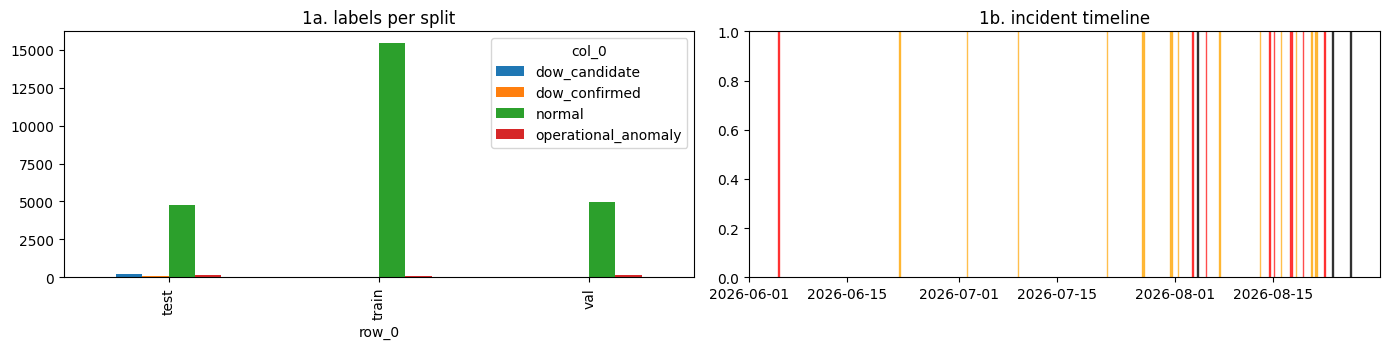

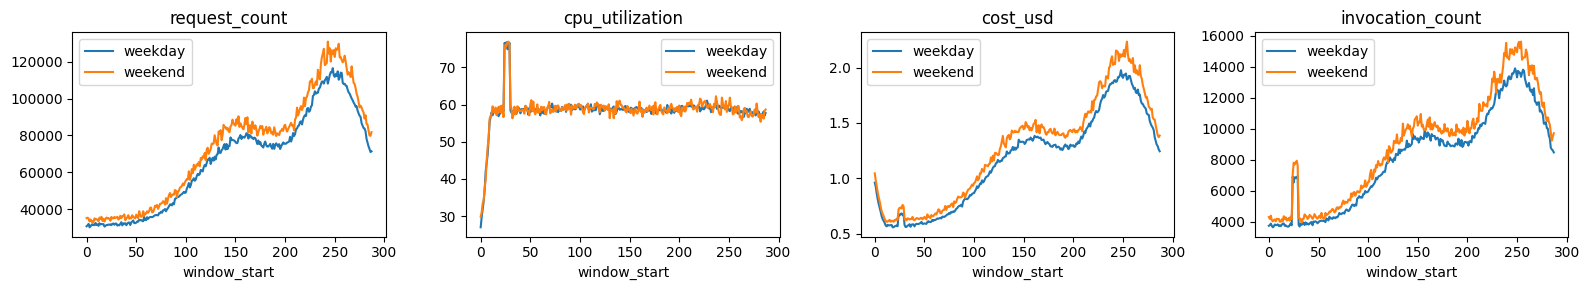

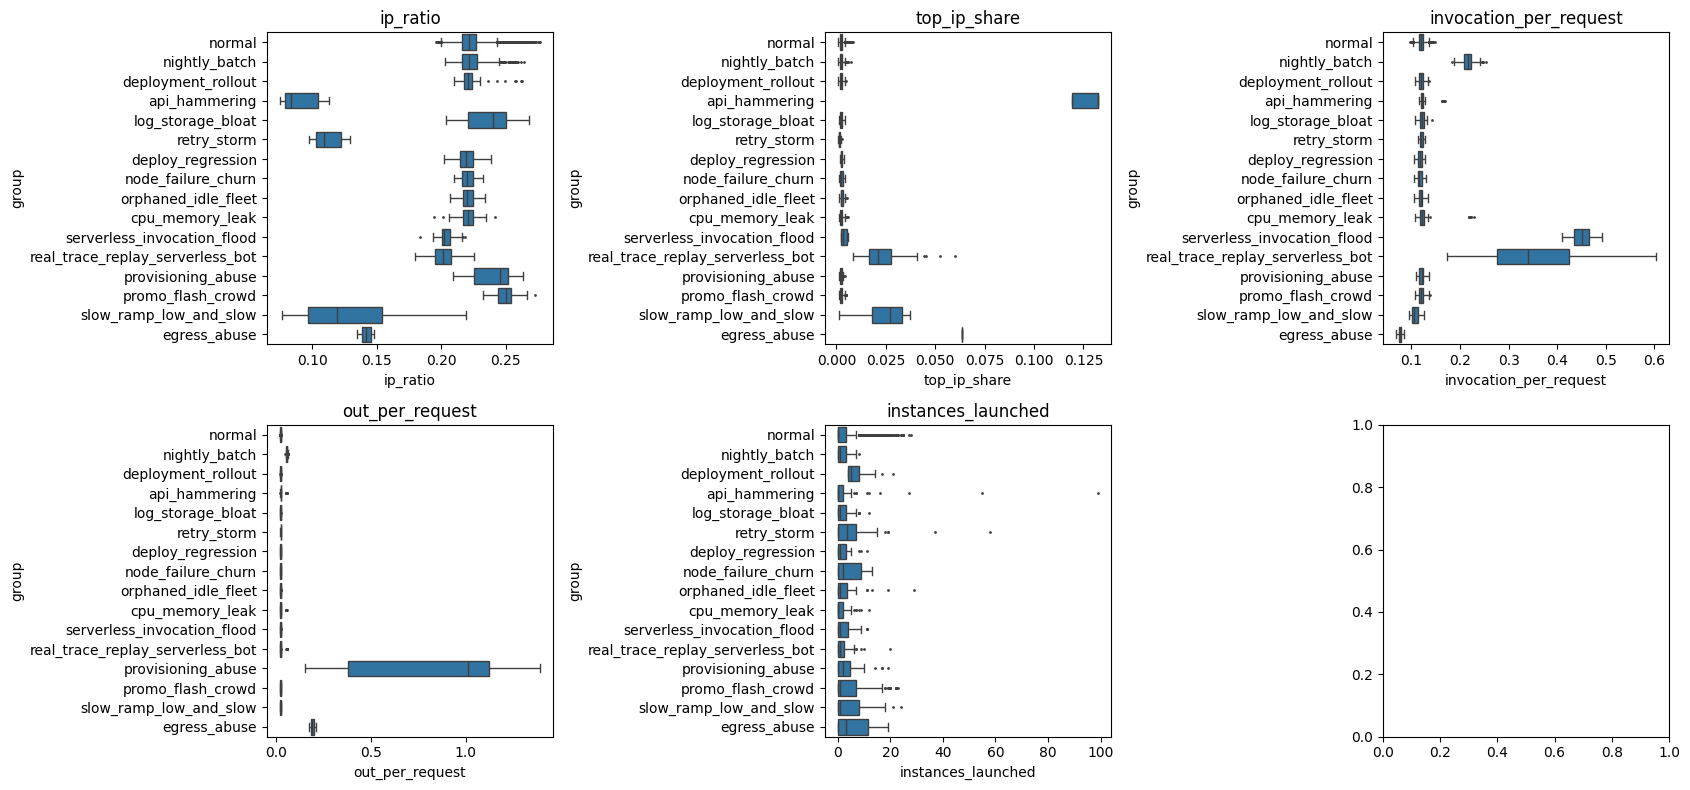

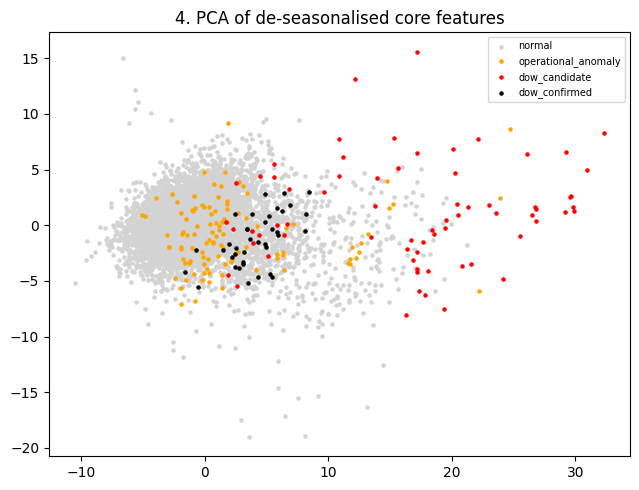

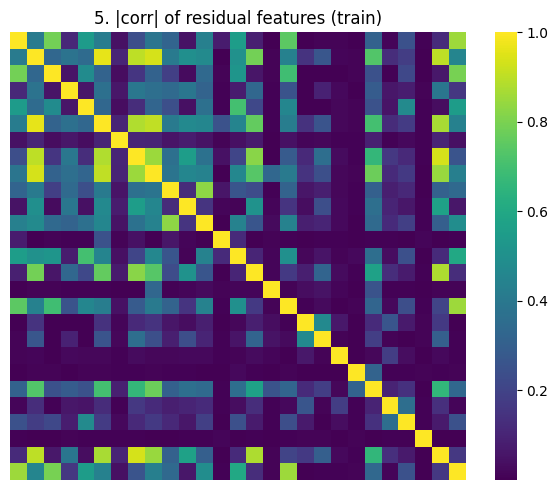

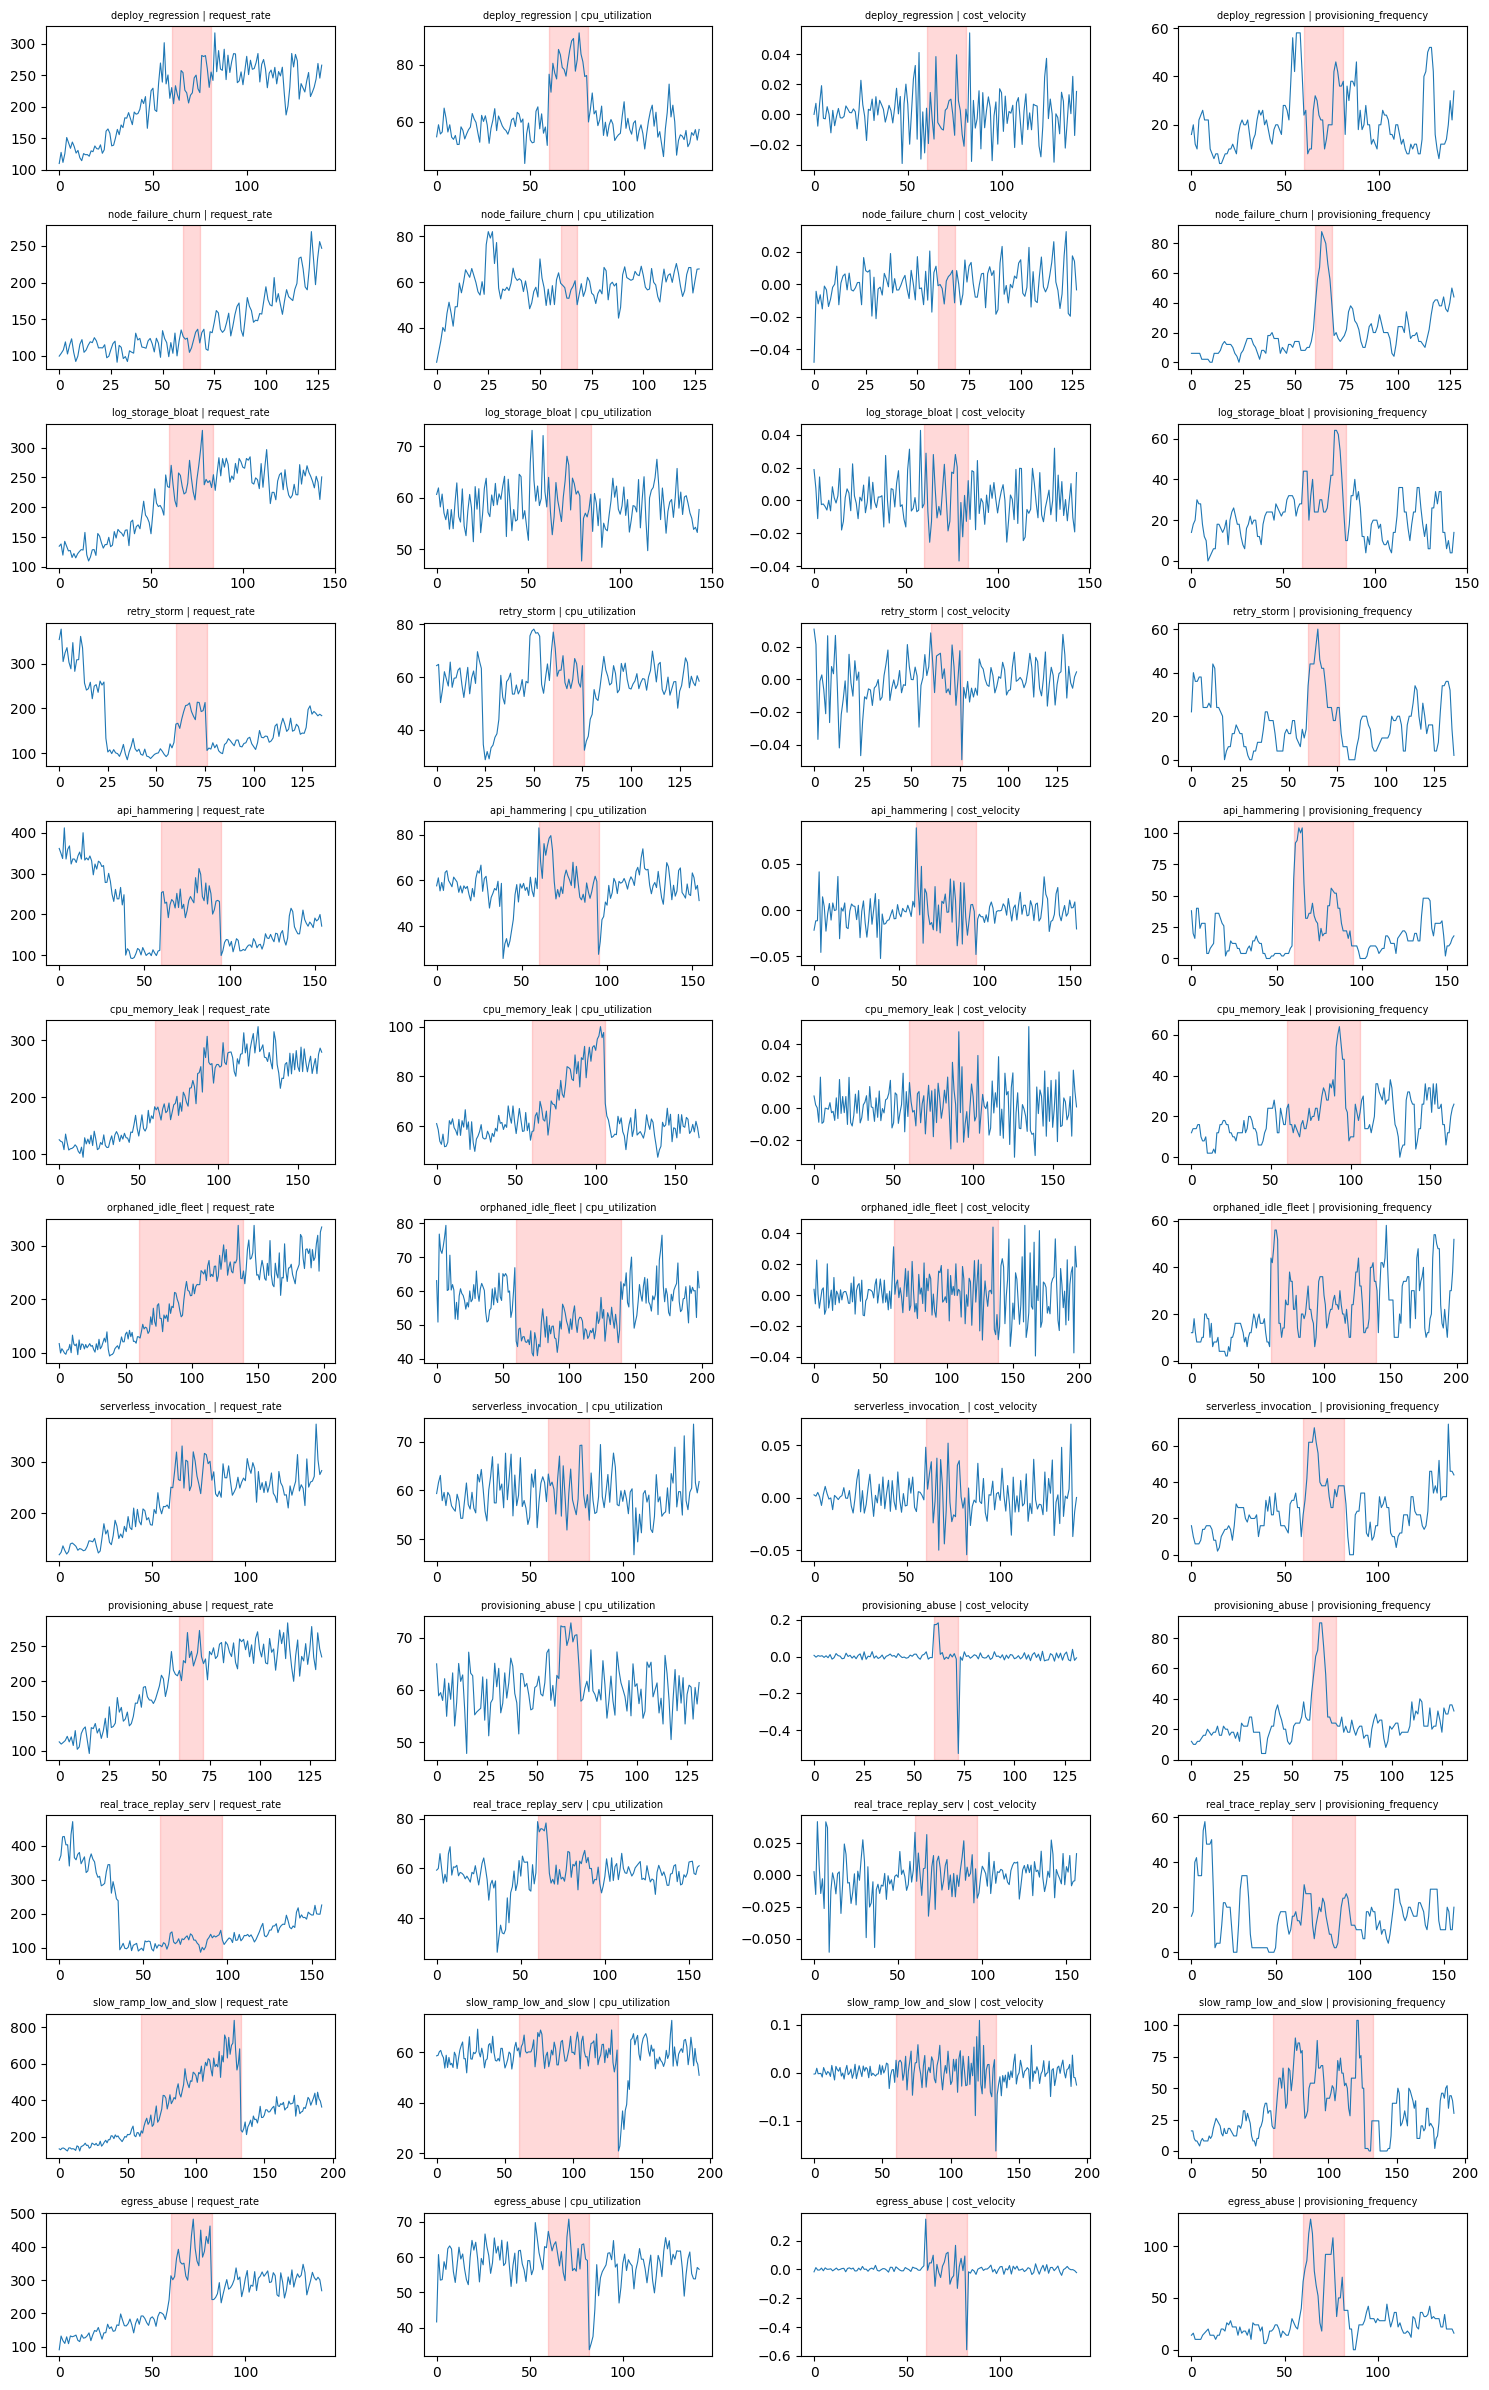

real Borg CPU log-residual spread 2.88 vs synthetic 0.077; share |robust z|>3.5: real 0.0% vs synthetic 0.8%. Dispersion profiles differ strongly -> thresholds tuned on synthetic data are NOT transferable; recalibrate on your own account.
NaN cells: {'cpu_utilization': 53, 'memory_utilization_pct': 53}


550

In [3]:
n = len(raw); i_tr = int(n * 0.6); S0 = an.fit_state(raw.iloc[:i_tr]); _, F_ = an._base(raw, S0); S1 = an.fit_seasonal(F_.iloc[:i_tr], raw.window_start.iloc[:i_tr]); FEe = an.build_features(raw, S0, S1)
L = labels.set_index("window_start").reindex(raw.window_start) if labels is not None else None; nm = (L.label == "normal").values if L is not None else np.ones(n, bool)
if L is not None:
    cols = {"operational_anomaly": "orange", "dow_candidate": "red", "dow_confirmed": "black"}; fig, axs = plt.subplots(1, 2, figsize=(14, 3.6)); pd.crosstab(np.where(np.arange(n) < i_tr, "train", np.where(np.arange(n) < int(n * .8), "val", "test")), L.label.values).plot.bar(ax=axs[0]); axs[0].set_title("1a. labels per split")
    for _, r in inc_gt.iterrows(): axs[1].axvspan(r.start, r.end, color=cols[r.label], alpha=.7)
    axs[1].set_title("1b. incident timeline"); savefig("01_balance_timeline", "Class balance and incidents")
sl = an.slot_of(raw.window_start); fig, axs = plt.subplots(1, 4, figsize=(16, 3))
for ax, c in zip(axs, ["request_count", "cpu_utilization", "cost_usd", "invocation_count"]):
    for wk, g_ in raw[nm].groupby(raw[nm].window_start.dt.dayofweek >= 5): g_.groupby(an.slot_of(g_.window_start))[c].median().plot(ax=ax, label="weekend" if wk else "weekday")
    ax.set_title(c); ax.legend()
savefig("02_daily_cycle", "Daily cycle (normal windows)")
if L is not None and "unique_ips" in raw:
    grp = np.where(L.attack_type.fillna("") != "", L.attack_type.fillna(""), np.where(L.context.fillna("none") != "none", L.context, "normal")); G = pd.DataFrame({"group": grp, "ip_ratio": F_.ip_ratio.values, "top_ip_share": raw.top_ip_share.values, "invocation_per_request": F_.invocation_per_request.values, "out_per_request": F_.out_per_request.values, "instances_launched": raw.instances_launched.values})
    fig, axs = plt.subplots(2, 3, figsize=(17, 8))
    for ax, c in zip(axs.ravel(), ["ip_ratio", "top_ip_share", "invocation_per_request", "out_per_request", "instances_launched"]): sns.boxplot(data=G, y="group", x=c, ax=ax, fliersize=1); ax.set_title(c)
    savefig("03_benign_vs_attack", "Benign look-alikes vs attacks")
from sklearn.decomposition import PCA
from sklearn.preprocessing import RobustScaler
fs = an.feature_sets(S0, FEe.columns); rc = fs["IF_core_resid"]; samp = np.random.default_rng(0).choice(n, 7000, replace=False); Z = PCA(2, random_state=0).fit_transform(np.clip(RobustScaler().fit(FEe.iloc[:i_tr][rc]).transform(FEe.iloc[samp][rc]), -10, 10))
fig, ax = plt.subplots(figsize=(6.5, 5))
if L is not None:
    lab = L.label.values[samp]
    for l_, c_ in [("normal", "lightgrey"), ("operational_anomaly", "orange"), ("dow_candidate", "red"), ("dow_confirmed", "black")]: ax.scatter(*Z[lab == l_].T, s=5, c=c_, label=l_)
    ax.legend(fontsize=7)
else: ax.scatter(*Z.T, s=4)
ax.set_title("4. PCA of de-seasonalised core features"); savefig("04_pca", "PCA coloured by label")
cm = FEe.iloc[:i_tr][fs["_resid_all"]].corr().abs(); fig, ax = plt.subplots(figsize=(6, 5)); sns.heatmap(cm, ax=ax, cmap="viridis", xticklabels=False, yticklabels=False); ax.set_title("5. |corr| of residual features (train)"); savefig("05_corr", "Feature redundancy")
if L is not None:
    types = inc_gt.type.unique(); keyf = ["b_request_rate", "b_cpu_utilization", "b_cost_velocity", "b_provisioning_frequency"]; fig, axs = plt.subplots(len(types), 4, figsize=(15, 2.0 * len(types)))
    for i, t in enumerate(types):
        r = inc_gt[inc_gt.type == t].iloc[0]; a = int(np.where(raw.window_start == r.start)[0][0]); seg = slice(max(0, a - 60), a + int(r.n_windows) + 60)
        for j, f in enumerate(keyf): axs[i, j].plot(FEe[f].iloc[seg].values, lw=.8); axs[i, j].axvspan(min(60, a), min(60, a) + r.n_windows, color="red", alpha=.15); axs[i, j].set_title(f"{t[:22]} | {f[2:]}", fontsize=7)
    savefig("06_incident_panels", "Per-incident behaviour of the nine spec features")
b = borg.sort_values("window_index"); lb = np.log(b.cpu_avg_sum.clip(lower=1e-6)); rb = lb - lb.groupby(b.hour_of_day).transform("median"); zb = rb / (1.4826 * rb.abs().median()); zs = FEe.loc[nm, "r_cpu_utilization"]; heavy = lambda z: float((z.abs() > 3.5).mean())
BORG_TXT = f"real Borg CPU log-residual spread {rb.std():.2f} vs synthetic {an.signed_log(F_.cpu_utilization).sub(sl.map(S1['slot_med']['cpu_utilization'])).loc[nm].std():.3f}; share |robust z|>3.5: real {heavy(zb):.1%} vs synthetic {heavy(zs):.1%}. Dispersion profiles differ strongly -> thresholds tuned on synthetic data are NOT transferable; recalibrate on your own account."
print(BORG_TXT); print("NaN cells:", {k: int(v) for k, v in raw.isna().sum().items() if v})
open(OUT / "eda_summary.md", "w").write("""# EDA -> decisions
Strong daily cycle -> train-only seasonal residual features (deviation from time-of-day norm).
Benign look-alikes (flash crowds, nightly batch, rolling deploys) mimic attacks -> traffic-quality features (IP diversity) + calendar flags when available.
Anomaly share rises train->val->test -> report AUPRC with prevalence; tune threshold on validation only.
Residual features are correlated -> feature-group ensemble when extended columns exist.
Real Borg dispersion differs from synthetic -> recalibrate thresholds per environment.
""")

## 3. Train (three tiers)

In [4]:
t0 = time.time()
o_ext = an.train_anomaly(tele, labels, out_dir=ART / "model_registry" / "isoforest_extended", progress=print)                                   # tier 1: extended + labelled
core_tele = tele[an.CORE_C + [c for c in an.CAL_C if c in tele]]
o_core = an.train_anomaly(core_tele, labels, out_dir=ART / "model_registry" / "isoforest_core_only", progress=print)                             # tier 2: only CloudWatch-obtainable columns
o_unl = an.train_anomaly(core_tele, None, out_dir=ART / "model_registry" / "isoforest_unlabelled_core", progress=print)                          # tier 3: no labels at all
print(f"done in {time.time()-t0:.0f}s"); print("spec IsolationForest params:", an.IF_SPEC); print("deployed detector -> extended:", o_ext["best"], "| core-only:", o_core["best"], "| unlabelled:", o_unl["best"])

deployable detector chosen on VAL AUPRC: HYBRID_IF_zrule


deployable detector chosen on VAL AUPRC: HYBRID_IF_zrule


UNLABELLED mode: deployed IF_spec_resid (spec-primary Isolation Forest, de-seasonalised); threshold = alert budget 12.0/day on the calibration split


done in 17s
spec IsolationForest params: {'n_estimators': 200, 'contamination': 0.01, 'max_samples': 'auto', 'random_state': 42}
deployed detector -> extended: HYBRID_IF_zrule | core-only: HYBRID_IF_zrule | unlabelled: IF_spec_resid


## 4. Evaluation on the untouched test split

In [5]:
pd.set_option("display.width", 220); E = o_ext["eval"]; sp = o_ext["split"]; Y, YD, LAB, CTX = o_ext["Y"], o_ext["YD"], o_ext["LAB"], o_ext["CTX"]; SC, THR = o_ext["scores"], o_ext["thresholds"]
cols = ["model", "precision", "recall", "F1", "AUPRC", "prevalence", "AUROC"]
print("=== TEST, any anomaly (AUPRC must beat prevalence) ==="); print(E[(E.split == "test") & (E.task == "a_any_anomaly")][cols].round(3).to_string(index=False))
print("\n=== TEST, DoW (synthetic dow_candidate + real replay) vs normal ==="); print(E[(E.split == "test") & (E.task == "b_DoW_vs_normal")][cols].round(3).to_string(index=False))
print("\n=== TEST, REAL-trace replay (dow_confirmed) vs normal, reported SEPARATELY ==="); print(E[(E.split == "test") & (E.task == "c_confirmed_replay_vs_normal")][cols].round(3).to_string(index=False))
print("\n=== incident level (test): recall, delay, false alert windows/day ==="); print(o_ext["incident_summary"].round(3))
ie = o_ext["incident_eval"]; print("\nper-type recall for the deployed detector:", ie[ie.model == o_ext["best"]].groupby("type").detected.mean().round(2).to_dict())
# ---- core vs extended: what do you lose if you only have CloudWatch metrics?
cmp_ = pd.concat([x["eval"][(x["eval"].split == "test") & (x["eval"].task.isin(["a_any_anomaly", "b_DoW_vs_normal"]))].assign(tier=t) for t, x in [("extended(+logs)", o_ext), ("core-only(CloudWatch)", o_core)]]); print("\n=== tier comparison, test AUPRC ==="); print(cmp_.pivot_table(index=["task", "model"], columns="tier", values="AUPRC").round(3))

=== TEST, any anomaly (AUPRC must beat prevalence) ===
          model  precision  recall    F1  AUPRC  prevalence  AUROC
    IF_spec_raw      0.261   0.277 0.269  0.269       0.083  0.777
  IF_spec_resid      0.901   0.191 0.315  0.404       0.083  0.785
  IF_core_resid      0.431   0.321 0.368  0.436       0.083  0.818
   IF_ext_group      0.749   0.479 0.584  0.692       0.083  0.922
 BL_zscore_rule      0.876   0.791 0.831  0.824       0.083  0.944
HYBRID_IF_zrule      0.876   0.791 0.831  0.825       0.083  0.946
 BL_OneClassSVM      0.616   0.505 0.555  0.610       0.083  0.905
         BL_LOF      0.429   0.765 0.550  0.635       0.083  0.921

=== TEST, DoW (synthetic dow_candidate + real replay) vs normal ===
          model  precision  recall    F1  AUPRC  prevalence  AUROC
    IF_spec_raw      0.261   0.458 0.332  0.322       0.052  0.865
  IF_spec_resid      0.901   0.315 0.467  0.529       0.052  0.867
  IF_core_resid      0.429   0.527 0.473  0.570       0.052  0.898
   IF

benign-context false-positive rate on TEST:
                    IF_spec_resid  HYBRID_IF_zrule  BL_zscore_rule  IF_core_resid WITHOUT calendar  IF_core_resid WITH calendar
promo_flash_crowd           0.040             0.02            0.02                           0.610                        0.680
nightly_batch               0.000             0.00            0.00                           0.000                        0.000
deployment_rollout          0.000             0.00            0.00                           0.000                        0.000
none                        0.001             0.01            0.01                           0.027                        0.025



AUPRC(HYBRID_IF_zrule) minus AUPRC(other), day-block bootstrap [mean, 2.5%, 97.5%]:
                 mean     lo     hi
IF_spec_resid   0.421  0.181  0.723
IF_core_resid   0.378  0.146  0.668
BL_zscore_rule  0.001 -0.001  0.004
BL_OneClassSVM  0.209  0.027  0.388

contamination is a THRESHOLD control, not the attack rate:
 contamination split  precision  recall    F1  alerts_per_day
         0.001   val      0.545   0.079 0.138           1.833
         0.001  test      0.910   0.212 0.343           5.556
         0.003   val      0.205   0.115 0.147           7.056
         0.003  test      0.576   0.307 0.401          12.722
         0.010   val      0.110   0.167 0.133          19.222
         0.010  test      0.294   0.363 0.325          29.500
         0.030   val      0.086   0.251 0.128          36.944
         0.030  test      0.229   0.472 0.308          49.333
         0.100   val      0.104   0.568 0.176          69.056
         0.100  test      0.208   0.721 0.323          

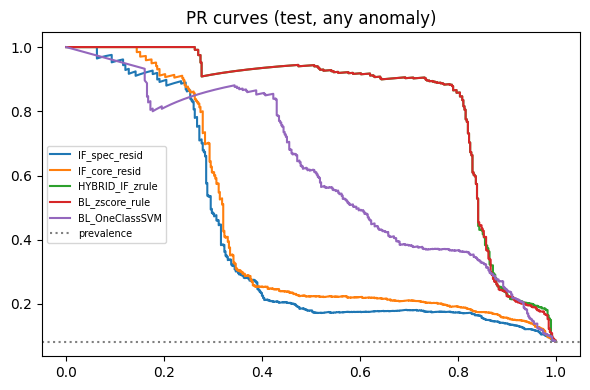


real-data robustness: real Borg CPU log-residual spread 2.88 vs synthetic 0.077; share |robust z|>3.5: real 0.0% vs synthetic 0.8%. Dispersion profiles differ strongly -> thresholds tuned on synthetic data are NOT transferable; recalibrate on your own account. This does NOT validate detection on real attacks.


In [6]:
# ---- benign false positives, calendar ablation, bootstrap CIs, sensitivity
trm = sp == "train"; te = sp == "test"; bn = {}
for k in dict.fromkeys(["IF_spec_resid", o_ext["best"], "BL_zscore_rule"]): al = SC[k] > THR[k]; bn[k] = {c: float(al[te & (CTX == c) & (LAB == "normal")].mean()) for c in ["promo_flash_crowd", "nightly_batch", "deployment_rollout", "none"]}
FEx = o_ext["FE"]; fs = o_ext["feature_sets"]; nocal = [c for c in fs["IF_core_resid"] if c not in an.CAL_C]; m_nc = an._if(FEx.loc[trm, nocal]); s_nc = -m_nc.score_samples(FEx[nocal]); thr_nc = an.choose_threshold_labelled(s_nc[sp == "val"], Y[sp == "val"], LAB[sp == "val"] == "normal", o_ext["n_days"]["val"], 15.0)
bn["IF_core_resid WITHOUT calendar"] = {c: float((s_nc > thr_nc)[te & (CTX == c) & (LAB == "normal")].mean()) for c in ["promo_flash_crowd", "nightly_batch", "deployment_rollout", "none"]}; bn["IF_core_resid WITH calendar"] = {c: float((SC["IF_core_resid"] > THR["IF_core_resid"])[te & (CTX == c) & (LAB == "normal")].mean()) for c in ["promo_flash_crowd", "nightly_batch", "deployment_rollout", "none"]}
print("benign-context false-positive rate on TEST:"); print(pd.DataFrame(bn).round(3))
days = raw.window_start.dt.date.values; ud = np.unique(days[te]); rg = np.random.default_rng(42); cis = {}
for base_ in [k for k in SC if k != o_ext["best"] and k in ("BL_zscore_rule", "BL_OneClassSVM", "IF_spec_resid", "IF_core_resid")]:
    dif = []
    for _ in range(200):
        idx = np.concatenate([np.where((days == d_) & te)[0] for d_ in rg.choice(ud, len(ud))]); yy = Y[idx]
        if yy.sum(): dif.append(average_precision_score(yy, SC[o_ext["best"]][idx]) - average_precision_score(yy, SC[base_][idx]))
    cis[base_] = (np.mean(dif), *np.percentile(dif, [2.5, 97.5]))
print(f"\nAUPRC({o_ext['best']}) minus AUPRC(other), day-block bootstrap [mean, 2.5%, 97.5%]:"); print(pd.DataFrame(cis, index=["mean", "lo", "hi"]).T.round(3))
sw = []
for c in [0.001, 0.003, 0.01, 0.03, 0.1]:
    t_ = np.quantile(SC["IF_core_resid"][trm], 1 - c); pr = SC["IF_core_resid"] > t_
    for s_ in ("val", "test"):
        m = sp == s_; tp = (pr & (Y == 1) & m).sum(); fp = (pr & (Y == 0) & m).sum(); fn = (~pr & (Y == 1) & m).sum(); P = tp / max(tp + fp, 1); R = tp / max(tp + fn, 1); sw.append(dict(contamination=c, split=s_, precision=P, recall=R, F1=2*P*R/max(P+R, 1e-9), alerts_per_day=pr[m].sum() / o_ext["n_days"][s_]))
print("\ncontamination is a THRESHOLD control, not the attack rate:"); print(pd.DataFrame(sw).round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(6, 4))
for k in ["IF_spec_resid", "IF_core_resid", o_ext["best"], "BL_zscore_rule", "BL_OneClassSVM"]: p_, r_, _ = precision_recall_curve(Y[te], SC[k][te]); ax.plot(r_, p_, label=k)
ax.axhline(Y[te].mean(), ls=":", c="grey", label="prevalence"); ax.legend(fontsize=7); ax.set_title("PR curves (test, any anomaly)"); savefig("13_pr_curves", "PR curves")
alert_rate = float((zb.abs() > 3.5).mean()); print("\nreal-data robustness:", BORG_TXT, "This does NOT validate detection on real attacks.")

## 5. Explainability, incident grouping and DoW triage

388 alerted test windows
2026-08-13 03:05:00 | log_storage_bloat -> Alert driven by storage_growth_rate +198.5 robust-z vs its time-of-day norm; ip_ratio +6.3 robust-z vs its time-of-day norm; cpu_per_request -4.3 robust-z vs its time-of-day norm; spend_vs_baseline +3.9 robust-z vs its time-of-day norm. (Isolation-Forest score is not a probability.)
2026-08-18 06:20:00 | node_failure_churn -> Alert driven by error_5xx_rate +34.0 robust-z vs its time-of-day norm; p95_latency_ms +13.7 robust-z vs its time-of-day norm; provisioning_frequency_2h +5.1 robust-z vs its time-of-day norm; provisioning_frequency +3.4 robust-z vs its time-of-day norm. (Isolation-Forest score is not a probability.)
2026-08-26 05:15:00 | real_trace_replay_serverless_bot -> Alert driven by top_ip_share +23.3 robust-z vs its time-of-day norm; avg_function_duration_ms +15.4 robust-z vs its time-of-day norm; lambda_concurrency_max +9.7 robust-z vs its time-of-day norm; invocation_per_request +8.8 robust-z vs its time-o

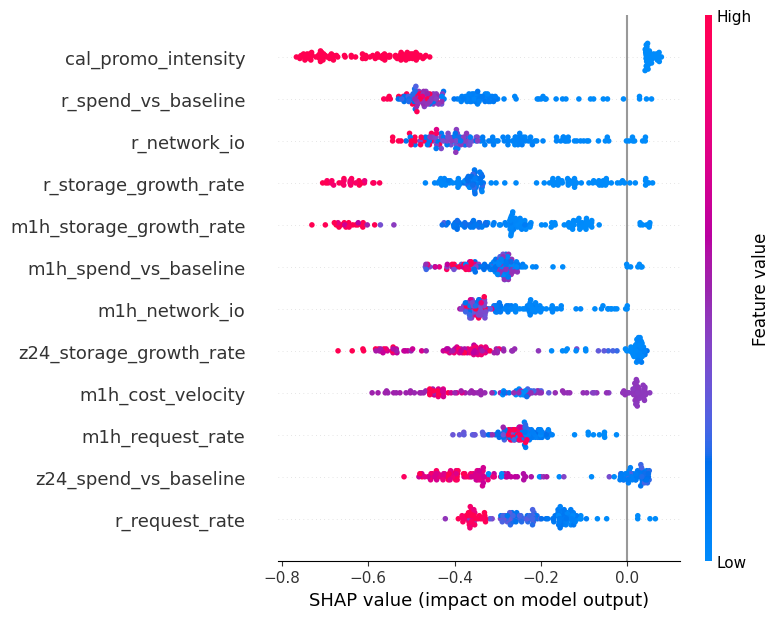

SHAP top features: {'cal_promo_intensity': 0.463, 'r_spend_vs_baseline': 0.385, 'r_network_io': 0.325, 'r_storage_growth_rate': 0.325, 'm1h_storage_growth_rate': 0.303, 'm1h_spend_vs_baseline': 0.301}

=== VAL triage vs truth (7 grouped alert incidents) ===
triage         dow_candidate  needs_review  operational
true_class                                             
dow_candidate              2             1            0
false_alert                0             1            0
operational                1             0            2

=== TEST triage vs truth (13 grouped alert incidents) ===
triage         dow_candidate  likely_legitimate_traffic  needs_review  operational
true_class                                                                        
dow_candidate              5                          1             1            0
false_alert                0                          2             0            0
operational                0                          1             0  

In [7]:
import shap
best = o_ext["best"]; sc_b, thr_b = SC[best], THR[best]; FEx = o_ext["FE"]; te_alert = np.where(te & (sc_b > thr_b))[0]; print(len(te_alert), "alerted test windows")
for i in te_alert[[0, len(te_alert) // 2, -1]]: print(raw.window_start[i], "|", (o_ext["L"].attack_type.iloc[i] or o_ext["L"].context.iloc[i]), "->", an.explain_alert(FEx.iloc[i])["sentence"])
try:                                              # SHAP TreeExplainer on the single-forest core model (sampled; ensemble members are explained group-wise)
    m_ = o_ext["models"]["IF_core_resid"]; cols_ = o_ext["feature_sets"]["IF_core_resid"]; ex = shap.TreeExplainer(m_, FEx.loc[trm, cols_].sample(100, random_state=0)); sa = FEx.loc[te_alert[:150], cols_]; sv_ = ex.shap_values(sa, check_additivity=False)
    plt.figure(); shap.summary_plot(sv_, sa, show=False, max_display=12); savefig("14_shap_alerts", "SHAP on alerted test windows"); print("SHAP top features:", pd.Series(np.abs(sv_).mean(0), index=cols_).sort_values(ascending=False).head(6).round(3).to_dict())
except Exception as e_: print("SHAP skipped:", e_)
def detect_incidents(o, split="test"):
    sc, thr, spm = o["scores"][o["best"]], o["thresholds"][o["best"]], o["split"] == split; al = (sc > thr) & spm; rows = []
    for gi, (a_, b_) in enumerate(an.group_alerts(al, 3)):
        seg = o["FE"].iloc[a_:b_ + 1]; promo = float(o["FE"]["cal_promo_intensity"].iloc[a_:b_ + 1].mean()) if "cal_promo_intensity" in o["FE"] else 0.0; cls, why = an.triage(seg, promo); tr_ = pd.Series(o["LAB"][a_:b_ + 1]); tr_ = tr_[tr_ != "normal"].mode()
        rows.append(dict(incident_id=f"ALERT{gi:03d}", start=o["raw"].window_start.iloc[a_], n_windows=b_ - a_ + 1, peak_score=float(sc[a_:b_ + 1].max()), triage=cls, reasons="; ".join(why), true=(tr_.iloc[0] if len(tr_) else "false_alert"),
                         severity="high" if cls == "dow_candidate" and b_ - a_ >= 6 else ("medium" if cls in ("dow_candidate", "operational") else "low")))
    return pd.DataFrame(rows)
for s_ in ("val", "test"):
    D_ = detect_incidents(o_ext, s_); D_["true_class"] = D_.true.map({"dow_candidate": "dow_candidate", "dow_confirmed": "dow_candidate", "operational_anomaly": "operational"}).fillna("false_alert")
    print(f"\n=== {s_.upper()} triage vs truth ({len(D_)} grouped alert incidents) ==="); print(pd.crosstab(D_.true_class, D_.triage))
    if s_ == "test": TEST_INC = D_
TEST_INC.to_csv(ART / "incidents_detected.csv", index=False)

## 6. Real-time scoring: StreamScorer + RealtimeRunner (and parity with batch)

In [8]:
scorer = an.StreamScorer.load(o_ext["bundle_dir"]); n0 = int(len(tele) * 0.8); req = scorer.b["required_cols"]
out = [scorer.update(tele.iloc[i][req].to_dict()) for i in range(n0 - 400, n0 + 120)]
batch = scorer.score_frame(tele.iloc[:n0 + 120]); got = np.array([r["score"] for r in out[-120:]]); print("max |stream - batch| score difference over 120 windows:", float(np.max(np.abs(got - batch.score.values[-120:]))))
print("example live output:", next((r for r in out if r["is_alert"]), out[-1]))
# RealtimeRunner demo: replay windows as if CloudWatch delivered them every 5 minutes (in production, fetch_window reads CloudWatch via cloudsense.collectors)
sc2 = an.StreamScorer.load(o_ext["bundle_dir"]); alerts_seen = []; by_ts = tele.set_index("window_start"); runner = RealtimeRunner(sc2, lambda w: {"window_start": w, **by_ts.loc[w][req[1:]].to_dict()}, on_alert=alerts_seen.append, lag_windows=2)
first = inc_gt[(inc_gt.split == "test") & (inc_gt.label != "operational_anomaly")].sort_values("start").iloc[0]; a_i = int(np.where(tele.window_start == first.start)[0][0])      # first DoW incident in the test period
runner.backfill(tele.iloc[: a_i - 10]); res_ = runner.step(tele.window_start.iloc[a_i + int(first.n_windows) + 3]); print(f"replaying a '{first.type}' incident ({first.n_windows} windows): runner scored {len(res_)} windows, raised {len(alerts_seen)} alert window(s); first alert: {alerts_seen[0]['window_start'] if alerts_seen else None} | triage {alerts_seen[0]['triage'] if alerts_seen else None}")

max |stream - batch| score difference over 120 windows: 0.0
example live output: {'window_start': '2026-08-10 14:40:00', 'score': 12.870131074032363, 'is_alert': True, 'severity': 'medium', 'top_features': [{'feature': 'provisioning_frequency_2h', 'robust_z': -16.58909939530632}, {'feature': 'storage_growth_rate', 'robust_z': -8.461147142862128}, {'feature': 'provisioning_frequency', 'robust_z': -6.620877497491292}, {'feature': 'ip_ratio', 'robust_z': 3.598380754676547}], 'incident_id': 'LIVE0001', 'triage': {'cls': 'operational', 'reasons': ['errors/latency/CPU/memory/storage/fleet deviation with normal traffic quality']}}


replaying a 'api_hammering' incident (36 windows): runner scored 48 windows, raised 38 alert window(s); first alert: 2026-08-14 09:50:00 | triage {'cls': 'dow_candidate', 'reasons': ['low IP diversity / concentrated sources with traffic or invocation surge']}


In [9]:
# ------------------------------ TESTS ------------------------------
assert not (set(sum([v for k, v in o_ext["feature_sets"].items() if not k.startswith("_")], [])) & set(an.FORBIDDEN)), "forbidden column used as feature"
p_ = o_ext["models"]["IF_spec_raw"].get_params(); assert (p_["n_estimators"], p_["contamination"], p_["max_samples"], p_["random_state"]) == (200, 0.01, "auto", 42), "spec parameters changed"
assert np.max(np.abs(got - batch.score.values[-120:])) < 1e-9, "stream/batch parity failed"
a_ = np.zeros(40, bool); a_[[3, 4, 7, 20]] = True; assert an.group_alerts(a_, 3) == [(3, 7), (20, 20)]
import joblib; assert abs(joblib.load(Path(o_ext["bundle_dir"]) / "bundle.joblib")["threshold"] - THR[best]) < 1e-12
try: scorer.update({"window_start": "2026-08-12"}); raise SystemExit("validation missing")
except ValueError: pass
try: an.validate_c(tele.assign(label="x")); raise SystemExit("label leakage not rejected")
except Exception as e_: assert "label" in str(e_)
assert o_unl["thresholds"][o_unl["best"]] > 0 and not o_unl["labelled"]
assert len(alerts_seen) > 0, "RealtimeRunner should alert during a replayed DoW incident"
print("all tests passed")

all tests passed


## 7. Report, zip and download

In [10]:
te_any = E[(E.split == "test") & (E.task == "a_any_anomaly")].set_index("model")[["precision", "recall", "F1", "AUPRC", "prevalence", "AUROC"]].round(3); te_dow = E[(E.split == "test") & (E.task == "b_DoW_vs_normal")].set_index("model")[["precision", "recall", "F1", "AUPRC", "prevalence"]].round(3)
te_rep = E[(E.split == "test") & (E.task == "c_confirmed_replay_vs_normal")].set_index("model")[["precision", "recall", "F1", "AUPRC", "prevalence"]].round(3)
bl = te_any[te_any.index.str.startswith("BL_")].AUPRC; ifs = te_any[te_any.index.str.startswith("IF_")].AUPRC
HONEST = (f"- Best Isolation-Forest variant AUPRC {ifs.max():.3f} ({ifs.idxmax()}) vs best baseline {bl.max():.3f} ({bl.idxmax()}); deployed detector `{best}` AUPRC {te_any.loc[best, 'AUPRC']:.3f} (prevalence {Y[te].mean():.3f}). " +
          ("A simple robust z-score rule beats the plain Isolation Forest on this synthetic data (injected anomalies are large single-feature deviations); the hybrid keeps the forest as the learned component and adds the rule as a safeguard.\n" if bl.max() > ifs.max() else "The Isolation Forest matches or beats the baselines.\n") +
          f"- Core-only (CloudWatch metrics) vs extended (+ access-log features) detector, test AUPRC any-anomaly: {o_core['eval'][(o_core['eval'].split=='test')&(o_core['eval'].task=='a_any_anomaly')].set_index('model').AUPRC.max():.3f} vs {te_any.AUPRC.max():.3f}: log-derived IP-diversity features matter for separating DoW from flash crowds.\n"
          f"- Calendar ablation, promo-flash-crowd FPR: without {bn['IF_core_resid WITHOUT calendar']['promo_flash_crowd']:.2f} vs with {bn['IF_core_resid WITH calendar']['promo_flash_crowd']:.2f}.\n- Unlabelled mode: threshold from an alert budget ({an.DEFAULT_CFG['alert_budget_per_day']}/day), no accuracy can be measured without labels.\n")
rep = f"""# Model C results: Isolation Forest anomaly + DoW detection
*Spec IsolationForest parameters {an.IF_SPEC}. Synthetic benchmark with a real-trace replay (unless replaced). Score is NOT a probability; alerts are DoW candidates, never confirmed attacks.*

## Setup
Chronological 60/20/20 split; fit on train only; threshold on validation only ({o_ext['bundle']['cfg']['fp_per_day_budget']} false-alert windows/day budget, max F1); test used once. Test anomaly share {Y[te].mean():.1%} (train {Y[trm].mean():.2%}).

## Test: any anomaly
{te_any.to_string()}

## Test: DoW vs normal
{te_dow.to_string()}

## Test: REAL-trace replay (dow_confirmed) vs normal
{te_rep.to_string()}

## Incident level (test)
{o_ext['incident_summary'].round(3).to_string()}

## Honest findings (computed from this run)
{HONEST}
## Real-data dispersion
{BORG_TXT}

## Limitations
Synthetic telemetry; 1-3 incidents per type per split; prevalence in val/test higher than real operations; cost per window is estimated on real AWS data; thresholds must be recalibrated on your account.
"""
open(OUT / "results_report.md", "w").write(rep); json.dump(CAPS, open(FIG / "captions.json", "w"), indent=1); E.to_csv(ART / "window_level_metrics.csv", index=False); o_ext["incident_summary"].to_csv(ART / "incident_level_summary.csv")
pd.DataFrame({"window_start": raw.window_start[te], "score": sc_b[te], "alert": (sc_b > thr_b)[te].astype(int)}).to_csv(ART / "test_scores.csv", index=False); print(rep)
def zip_and_download(out: Path, name: str):
    zp = Path(name)
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
        for p in out.rglob("*"):
            if p.is_file(): z.write(p, p.relative_to(out.parent))
    print("zipped ->", zp.resolve(), f"({zp.stat().st_size/1e6:.1f} MB)")
    try:
        from google.colab import files; files.download(str(zp))              # Colab: browser download
    except ImportError: print("Not on Colab: the zip is in the working folder.")
zip_and_download(OUT, "model_C_isolation_forest_artifacts.zip")

# Model C results: Isolation Forest anomaly + DoW detection
*Spec IsolationForest parameters {'n_estimators': 200, 'contamination': 0.01, 'max_samples': 'auto', 'random_state': 42}. Synthetic benchmark with a real-trace replay (unless replaced). Score is NOT a probability; alerts are DoW candidates, never confirmed attacks.*

## Setup
Chronological 60/20/20 split; fit on train only; threshold on validation only (15.0 false-alert windows/day budget, max F1); test used once. Test anomaly share 8.3% (train 0.67%).

## Test: any anomaly
                 precision  recall     F1  AUPRC  prevalence  AUROC
model                                                              
IF_spec_raw          0.261   0.277  0.269  0.269       0.083  0.777
IF_spec_resid        0.901   0.191  0.315  0.404       0.083  0.785
IF_core_resid        0.431   0.321  0.368  0.436       0.083  0.818
IF_ext_group         0.749   0.479  0.584  0.692       0.083  0.922
BL_zscore_rule       0.876   0.791  0.831  0.824     

zipped -> /mnt/user-data/outputs/cloudsense_ml/notebooks/model_C_isolation_forest_artifacts.zip (5.7 MB)
Not on Colab: the zip is in the working folder.
